
# NQ_IBB_Robustness

## 1.1 Purpose

This notebook stress-tests the NQ IBB strategy built in `NQ_IBB_Development.ipynb`,
following the TIS robustness methodology (see `Modulo_6_5.md`, `Modulo_7.md`):

- **Out-of-sample validation**: minimum 30% of data reserved and never used to
  choose parameters (`Modulo_6_5.md`: *"Pruebas de robustez fuera de muestra
  (mínimo 30% de datos reservados)"*).
- **Walk-forward analysis**: rolling in-sample/out-of-sample windows, to check
  whether performance survives outside a single lucky sample
  (`Modulo_7.md`: *"Si tu estrategia no puede mantener performance consistente
  en walk-forward, es puro curve fitting."*).
- **Monte Carlo simulation**: minimum 10,000 resamples of the realized trade
  sequence, to characterize the distribution of plausible outcomes, not just
  the single historical path (`Modulo_6_5.md`: *"Realizar mínimo 10,000
  simulaciones"*).
- **Parameter sensitivity**: perturb `ib_pct_min`, `tp_mult`, `sl_mult` around
  the blueprint defaults and confirm the edge doesn't collapse at small
  changes (a fragile edge that only works at one exact parameter set is a
  red flag for curve-fitting).
- **Sub-period stability**: year-by-year breakdown, checking the edge isn't
  carried by one anomalous year (e.g. 2020 COVID volatility).

This notebook imports the *same* `ibb_engine.py` used in the development
notebook -- no reimplementation, no drift between "what we built" and "what
we're stress-testing."


In [1]:

import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

utils_path = os.path.abspath('../../utils')
if utils_path not in sys.path:
    sys.path.insert(0, utils_path)
from utils import load_data_from_mongo, to_session_date

sys.path.insert(0, os.path.abspath('.'))
from ibb_engine import IBBConfig, run_backtest, compute_metrics, print_metrics_table

print("Imports and configuration complete.")


Imports and configuration complete.


## 1.2 Load Data & Base Config (identical to development notebook)

In [2]:

df_raw = load_data_from_mongo('nq_15min')
df_raw = df_raw.copy()
df_raw['session_date'] = [to_session_date(ts) for ts in df_raw.index]
print(f"Sessions available: {df_raw['session_date'].nunique()}")

base_cfg = IBBConfig(
    ib_start="09:30", ib_end_exclusive="10:30",
    entry_window_start="10:30", entry_window_end="13:30",
    forced_close_time="15:30",      # <-- actualizar
    ib_pct_min=0.75,                 # <-- actualizar
    ib_pct_extreme=2.00,
    tp_mult=0.60, sl_mult=0.40,
    entry_mode="close",              # <-- actualizar
    max_trades_per_session=1,
    point_value=20.0, contracts=1,
    slippage_points=1.00, commission_points=0.30,
)

Sessions available: 4386



## 2. Out-Of-Sample Split (70 / 30)

Reserve the most recent 30% of sessions as a true holdout: no parameter in
this notebook is chosen by looking at it. All sensitivity/walk-forward work
below operates on the in-sample slice; the OOS slice is only touched once,
at the end, to confirm the final chosen configuration.


In [3]:

all_sessions = sorted(df_raw['session_date'].unique())
split_idx = int(len(all_sessions) * 0.70)
is_sessions = set(all_sessions[:split_idx])
oos_sessions = set(all_sessions[split_idx:])

df_is = df_raw[df_raw['session_date'].isin(is_sessions)]
df_oos = df_raw[df_raw['session_date'].isin(oos_sessions)]

print(f"In-sample:      {min(is_sessions)} \u2192 {max(is_sessions)}  ({len(is_sessions)} sessions)")
print(f"Out-of-sample:  {min(oos_sessions)} \u2192 {max(oos_sessions)}  ({len(oos_sessions)} sessions, "
      f"{len(oos_sessions)/len(all_sessions)*100:.1f}% of total)")


In-sample:      2009-09-28 → 2021-08-13  (3070 sessions)
Out-of-sample:  2021-08-16 → 2026-08-28  (1316 sessions, 30.0% of total)


In [4]:

trades_is = run_backtest(df_is, base_cfg)
metrics_is = compute_metrics(trades_is)
print_metrics_table(metrics_is, label="IN-SAMPLE (blueprint defaults)")


IBB METRICS -- IN-SAMPLE (blueprint defaults)
total_sessions          : 3062
total_trades            : 853
trade_frequency_pct     : 27.858
win_rate_pct            : 49.824
avg_win_pct             : 0.522
avg_loss_pct            : -0.451
payoff_ratio            : 1.160
profit_factor           : 1.309
total_return_pct        : 64.971
max_drawdown_pct        : -5.605
expectancy_usd          : 76.168
avg_hold_minutes        : 122.866
final_equity            : 164,971.000


In [5]:

trades_oos = run_backtest(df_oos, base_cfg)
metrics_oos = compute_metrics(trades_oos)
print_metrics_table(metrics_oos, label="OUT-OF-SAMPLE (blueprint defaults, untouched)")


IBB METRICS -- OUT-OF-SAMPLE (blueprint defaults, untouched)
total_sessions          : 1299
total_trades            : 546
trade_frequency_pct     : 42.032
win_rate_pct            : 57.509
avg_win_pct             : 0.588
avg_loss_pct            : -0.428
payoff_ratio            : 1.374
profit_factor           : 1.810
total_return_pct        : 258.486
max_drawdown_pct        : -5.611
expectancy_usd          : 473.418
avg_hold_minutes        : 119.341
final_equity            : 358,486.000



### 2.1 In-Sample vs. Out-of-Sample Comparison

Per `Modulo_7.md`: a "diferencia dramática" between in-sample and
out-of-sample performance is the classic curve-fitting signature. Compare
win rate, profit factor, and expectancy side by side -- large, one-directional
degradation (not just noise) is the flag to watch for.


In [6]:

compare_cols = ['total_trades', 'win_rate_pct', 'payoff_ratio', 'profit_factor',
                 'total_return_pct', 'max_drawdown_pct', 'expectancy_usd']
compare_df = pd.DataFrame({
    'In-Sample': {k: metrics_is.get(k, np.nan) for k in compare_cols},
    'Out-of-Sample': {k: metrics_oos.get(k, np.nan) for k in compare_cols},
})
compare_df['Delta'] = compare_df['Out-of-Sample'] - compare_df['In-Sample']
compare_df


,In-Sample,Out-of-Sample,Delta
total_trades,853.000000,546.000000,-307.000000
win_rate_pct,49.824150,57.509158,7.685007
payoff_ratio,1.159526,1.374484,0.214958
profit_factor,1.309446,1.810164,0.500718
total_return_pct,64.971000,258.486000,193.515000
max_drawdown_pct,-5.604998,-5.611320,-0.006322
expectancy_usd,76.167644,473.417582,397.249939


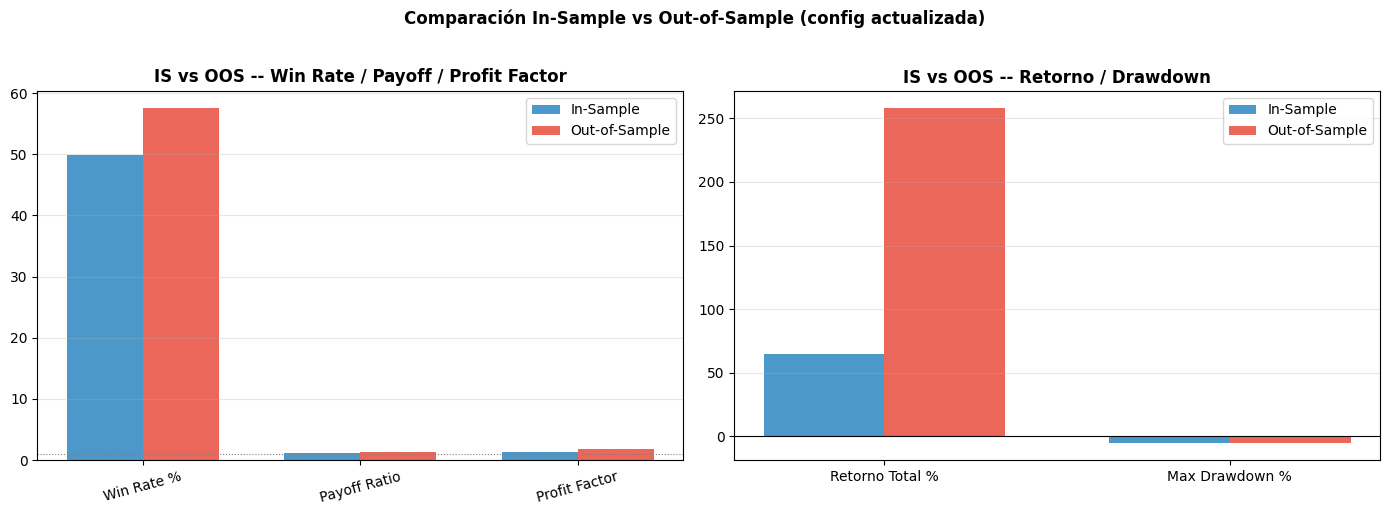

In [7]:
# --- Gráfico: In-Sample vs Out-of-Sample ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: métricas de "tasa" (comparables en la misma escala 0-100 o ratio)
rate_metrics = ['win_rate_pct', 'payoff_ratio', 'profit_factor']
x = np.arange(len(rate_metrics))
width = 0.35

is_vals = [metrics_is.get(m, np.nan) for m in rate_metrics]
oos_vals = [metrics_oos.get(m, np.nan) for m in rate_metrics]

axes[0].bar(x - width/2, is_vals, width, label='In-Sample', color='#2E86C1', alpha=0.85)
axes[0].bar(x + width/2, oos_vals, width, label='Out-of-Sample', color='#E74C3C', alpha=0.85)
axes[0].axhline(1.0, color='gray', linestyle=':', linewidth=0.8)
axes[0].set_xticks(x)
axes[0].set_xticklabels(['Win Rate %', 'Payoff Ratio', 'Profit Factor'], rotation=15)
axes[0].set_title('IS vs OOS -- Win Rate / Payoff / Profit Factor', fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')

# Panel 2: retorno total y max drawdown (escala distinta, van juntos por %)
ret_dd_metrics = ['total_return_pct', 'max_drawdown_pct']
x2 = np.arange(len(ret_dd_metrics))
is_vals2 = [metrics_is.get(m, np.nan) for m in ret_dd_metrics]
oos_vals2 = [metrics_oos.get(m, np.nan) for m in ret_dd_metrics]

axes[1].bar(x2 - width/2, is_vals2, width, label='In-Sample', color='#2E86C1', alpha=0.85)
axes[1].bar(x2 + width/2, oos_vals2, width, label='Out-of-Sample', color='#E74C3C', alpha=0.85)
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_xticks(x2)
axes[1].set_xticklabels(['Retorno Total %', 'Max Drawdown %'])
axes[1].set_title('IS vs OOS -- Retorno / Drawdown', fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

plt.suptitle('Comparación In-Sample vs Out-of-Sample (config actualizada)', fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

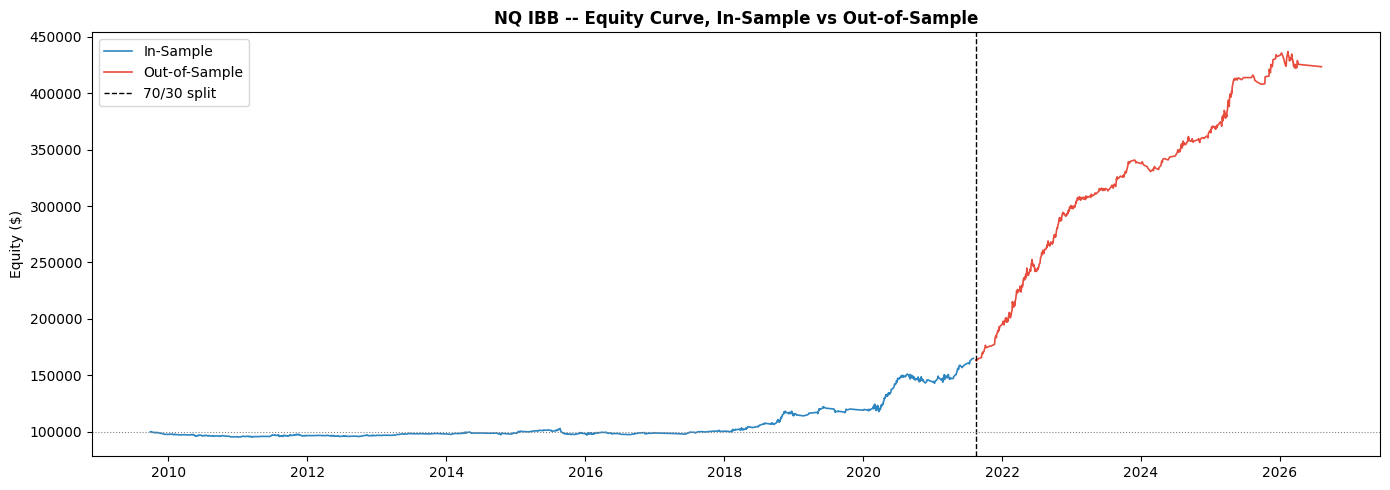

In [8]:
# --- Chart: continuous equity curve, colored by In-Sample vs Out-of-Sample ---
split_date = min(oos_sessions)

traded_full_cmp = pd.concat([trades_is[trades_is['traded']], trades_oos[trades_oos['traded']]])
traded_full_cmp = traded_full_cmp.sort_values('entry_time').reset_index(drop=True)
equity_cmp = 100_000 + traded_full_cmp['pnl_usd'].cumsum()

is_mask = traded_full_cmp['entry_time'] < pd.Timestamp(split_date)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(traded_full_cmp.loc[is_mask, 'entry_time'], equity_cmp[is_mask],
        color='#2E86C1', linewidth=1.2, label='In-Sample')
ax.plot(traded_full_cmp.loc[~is_mask, 'entry_time'], equity_cmp[~is_mask],
        color='#E74C3C', linewidth=1.2, label='Out-of-Sample')
ax.axvline(pd.Timestamp(split_date), color='black', linestyle='--', linewidth=1, label='70/30 split')
ax.axhline(100_000, color='gray', linestyle=':', linewidth=0.8)
ax.set_title('NQ IBB -- Equity Curve, In-Sample vs Out-of-Sample', fontweight='bold')
ax.set_ylabel('Equity ($)')
ax.legend()
plt.tight_layout()
plt.show()


## 3. Walk-Forward Analysis

Rolling windows: optimize `ib_pct_min` on each in-sample block (small grid,
avoiding excessive parameter search per `Modulo_7.md`'s curve-fitting
warning), then test that chosen parameter on the *next*, unseen block. This
directly answers whether performance is consistent walk-forward or whether
it's an artifact of the specific historical sample.


In [9]:

def walk_forward(df, sessions, cfg_base, param_grid, n_folds=6, is_frac=0.7):
    '''Simple rolling walk-forward: split sessions into n_folds contiguous
    blocks; for each block, optimize param_grid on the first is_frac of the
    block (by profit factor) and test on the remaining out-of-sample tail.'''
    sessions = sorted(sessions)
    fold_size = len(sessions) // n_folds
    results = []

    for fold in range(n_folds):
        fold_sessions = sessions[fold * fold_size: (fold + 1) * fold_size]
        if len(fold_sessions) < 20:
            continue
        split = int(len(fold_sessions) * is_frac)
        is_block = set(fold_sessions[:split])
        oos_block = set(fold_sessions[split:])

        df_is_block = df[df['session_date'].isin(is_block)]
        df_oos_block = df[df['session_date'].isin(oos_block)]

        best_pf, best_param = -np.inf, param_grid[0]
        for p in param_grid:
            cfg_try = IBBConfig(**{**cfg_base.__dict__, "ib_pct_min": p})
            t = run_backtest(df_is_block, cfg_try)
            m = compute_metrics(t)
            pf = m.get('profit_factor', np.nan)
            if np.isfinite(pf) and pf > best_pf and m.get('total_trades', 0) >= 5:
                best_pf, best_param = pf, p

        cfg_oos = IBBConfig(**{**cfg_base.__dict__, "ib_pct_min": best_param})
        t_oos = run_backtest(df_oos_block, cfg_oos)
        m_oos = compute_metrics(t_oos)

        results.append({
            "fold": fold + 1,
            "is_start": fold_sessions[0], "is_end": fold_sessions[split - 1],
            "oos_start": fold_sessions[split], "oos_end": fold_sessions[-1],
            "chosen_ib_pct_min": best_param,
            "oos_trades": m_oos.get('total_trades', 0),
            "oos_win_rate_pct": m_oos.get('win_rate_pct', np.nan),
            "oos_profit_factor": m_oos.get('profit_factor', np.nan),
            "oos_total_return_pct": m_oos.get('total_return_pct', np.nan),
            "oos_max_dd_pct": m_oos.get('max_drawdown_pct', np.nan),
        })

    return pd.DataFrame(results)

param_grid = [0.40, 0.55, 0.70, 0.85, 1.00]
wf_results = walk_forward(df_raw, all_sessions, base_cfg, param_grid, n_folds=6)
wf_results


,fold,is_start,is_end,oos_start,oos_end,chosen_ib_pct_min,oos_trades,oos_win_rate_pct,oos_profit_factor,oos_total_return_pct,oos_max_dd_pct
0,1,2009-09-28,2011-09-16,2011-09-19,2012-07-24,0.85,64,51.562500,1.207496,1.301,-1.175428
1,2,2012-07-25,2014-07-16,2014-07-17,2015-05-22,1.00,17,58.823529,1.221859,0.611,-0.851811
2,3,2015-05-25,2017-05-16,2017-05-17,2018-03-22,1.00,11,63.636364,2.054320,2.465,-0.897677
3,4,2018-03-23,2020-03-16,2020-03-17,2021-01-21,0.85,101,55.445545,1.417149,21.605,-6.825853
4,5,2021-01-22,2023-01-12,2023-01-13,2023-11-16,0.85,66,59.090909,2.278824,36.137,-3.366259
5,6,2023-11-17,2025-11-10,2025-11-11,2026-08-28,1.00,25,60.000000,1.631086,14.946,-8.090316


In [10]:

print("Walk-forward summary:")
print(f"  Folds with profit_factor > 1.0: {(wf_results['oos_profit_factor'] > 1.0).sum()} / {len(wf_results)}")
print(f"  Mean OOS profit factor: {wf_results['oos_profit_factor'].mean():.3f}")
print(f"  Mean OOS total return:  {wf_results['oos_total_return_pct'].mean():.2f}%")
print(f"  Std  OOS total return:  {wf_results['oos_total_return_pct'].std():.2f}%")
print("\nA robust edge shows OOS profit factor consistently > 1.0 across most/all folds,")
print("without extreme dependence on which fold's IB%-min happened to be chosen.")


Walk-forward summary:
  Folds with profit_factor > 1.0: 6 / 6
  Mean OOS profit factor: 1.635
  Mean OOS total return:  12.84%
  Std  OOS total return:  14.24%

A robust edge shows OOS profit factor consistently > 1.0 across most/all folds,
without extreme dependence on which fold's IB%-min happened to be chosen.


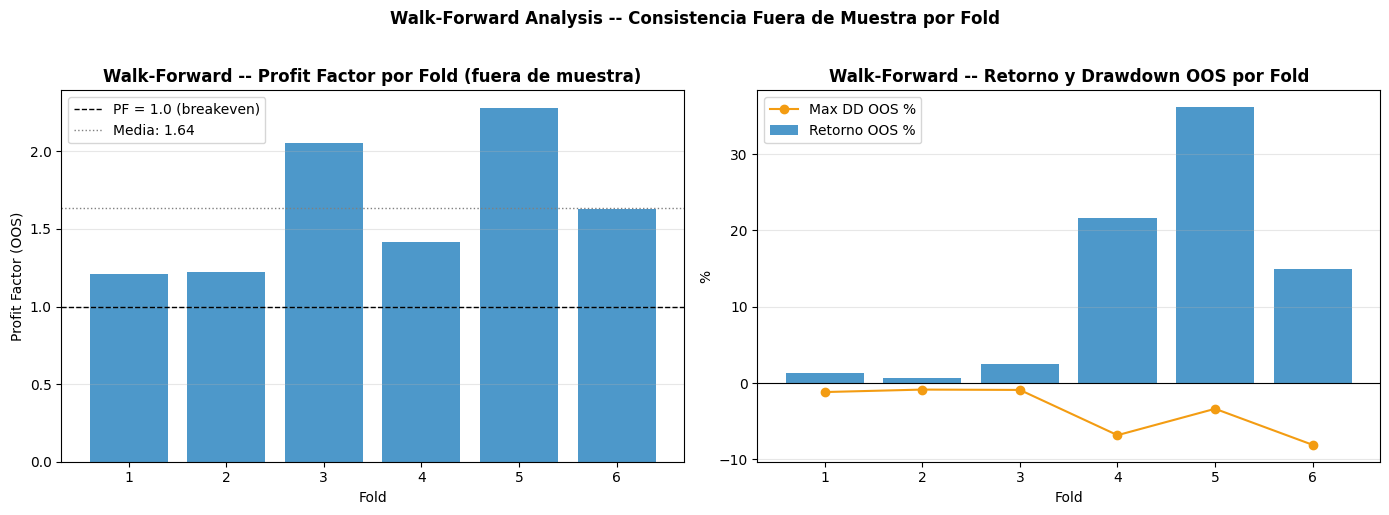

In [11]:
# --- Gráfico: Walk-Forward por fold ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

folds = wf_results['fold'].astype(str)

# Panel 1: Profit Factor OOS por fold
colors_pf = ['#2E86C1' if pf >= 1.0 else '#E74C3C' for pf in wf_results['oos_profit_factor']]
axes[0].bar(folds, wf_results['oos_profit_factor'], color=colors_pf, alpha=0.85)
axes[0].axhline(1.0, color='black', linestyle='--', linewidth=1, label='PF = 1.0 (breakeven)')
axes[0].axhline(wf_results['oos_profit_factor'].mean(), color='gray', linestyle=':',
                linewidth=1, label=f"Media: {wf_results['oos_profit_factor'].mean():.2f}")
axes[0].set_xlabel('Fold')
axes[0].set_ylabel('Profit Factor (OOS)')
axes[0].set_title('Walk-Forward -- Profit Factor por Fold (fuera de muestra)', fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')

# Panel 2: Retorno total OOS por fold, con barra de error implícita vía DD
colors_ret = ['#2E86C1' if r >= 0 else '#E74C3C' for r in wf_results['oos_total_return_pct']]
axes[1].bar(folds, wf_results['oos_total_return_pct'], color=colors_ret, alpha=0.85, label='Retorno OOS %')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].plot(folds, wf_results['oos_max_dd_pct'], color='#F39C12', marker='o',
             linewidth=1.5, label='Max DD OOS %')
axes[1].set_xlabel('Fold')
axes[1].set_ylabel('%')
axes[1].set_title('Walk-Forward -- Retorno y Drawdown OOS por Fold', fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

plt.suptitle('Walk-Forward Analysis -- Consistencia Fuera de Muestra por Fold', fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

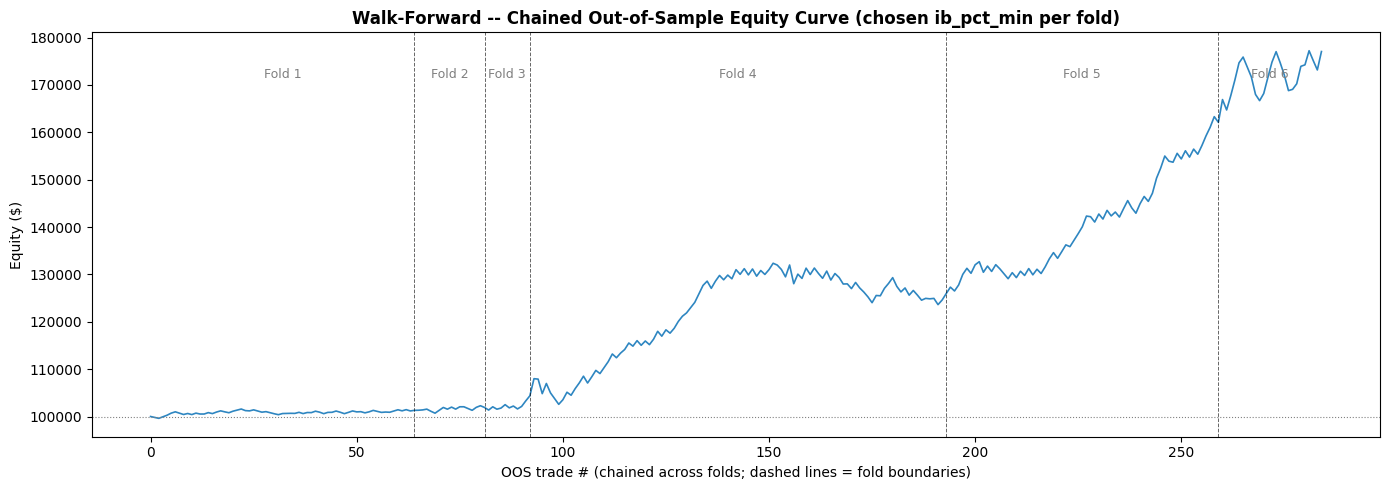

In [12]:
# --- Walk-forward equity curve: chain the OOS legs of each fold in chronological order ---
# Re-runs the same optimize-then-test logic as walk_forward(), but keeps the trade-level
# OOS results so we can plot an equity curve, not just per-fold summary stats.
def walk_forward_with_trades(df, sessions, cfg_base, param_grid, n_folds=6, is_frac=0.7):
    sessions = sorted(sessions)
    fold_size = len(sessions) // n_folds
    oos_trades_by_fold = {}
    for fold in range(n_folds):
        fold_sessions = sessions[fold * fold_size: (fold + 1) * fold_size]
        if len(fold_sessions) < 20:
            continue
        split = int(len(fold_sessions) * is_frac)
        is_block = set(fold_sessions[:split])
        oos_block = set(fold_sessions[split:])
        df_is_block = df[df['session_date'].isin(is_block)]
        df_oos_block = df[df['session_date'].isin(oos_block)]

        best_pf, best_param = -np.inf, param_grid[0]
        for p in param_grid:
            cfg_try = IBBConfig(**{**cfg_base.__dict__, "ib_pct_min": p})
            t = run_backtest(df_is_block, cfg_try)
            m = compute_metrics(t)
            pf = m.get('profit_factor', np.nan)
            if np.isfinite(pf) and pf > best_pf and m.get('total_trades', 0) >= 5:
                best_pf, best_param = pf, p

        cfg_oos = IBBConfig(**{**cfg_base.__dict__, "ib_pct_min": best_param})
        t_oos = run_backtest(df_oos_block, cfg_oos)
        oos_trades_by_fold[fold + 1] = t_oos[t_oos['traded']].sort_values('entry_time').reset_index(drop=True)
    return oos_trades_by_fold

wf_trades_by_fold = walk_forward_with_trades(df_raw, all_sessions, base_cfg, param_grid, n_folds=6)

# Chain the OOS legs on a trade-index axis (calendar time has IS gaps between folds)
starting_equity = 100_000.0
equity_points = [starting_equity]
fold_boundaries = [0]
for fold_num, t in wf_trades_by_fold.items():
    equity_points.extend((equity_points[-1] + t['pnl_usd'].cumsum()).tolist())
    fold_boundaries.append(len(equity_points) - 1)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(equity_points, color='#2E86C1', linewidth=1.2)
ax.axhline(starting_equity, color='gray', linestyle=':', linewidth=0.8)
for b in fold_boundaries[1:-1]:
    ax.axvline(b, color='black', linestyle='--', linewidth=0.7, alpha=0.6)
for i, (start, end) in enumerate(zip(fold_boundaries[:-1], fold_boundaries[1:]), start=1):
    ax.text((start + end) / 2, max(equity_points) * 0.98, f"Fold {i}",
            ha='center', va='top', fontsize=9, color='gray')
ax.set_title('Walk-Forward -- Chained Out-of-Sample Equity Curve (chosen ib_pct_min per fold)',
             fontweight='bold')
ax.set_xlabel('OOS trade # (chained across folds; dashed lines = fold boundaries)')
ax.set_ylabel('Equity ($)')
plt.tight_layout()
plt.show()


## 4. Monte Carlo Simulation

Bootstrap-resamples the realized trade P&L sequence (from the full-sample,
cost-adjusted backtest) >= 10,000 times per `Modulo_6_5.md`'s minimum, to
characterize the *distribution* of terminal equity and max drawdown --
not just the single historical path, which is one draw from that
distribution.

Two variants are run:
- **IID bootstrap**: resample individual trade P&Ls with replacement
  (destroys trade-order/streak effects -- best case answer to "how bad can
  variance alone get me").
- **Block bootstrap**: resample contiguous blocks of trades (preserves local
  streakiness/autocorrelation -- more realistic worst-case for drawdown).


In [13]:

trades_full = run_backtest(df_raw, base_cfg)
traded_full = trades_full[trades_full['traded']].sort_values('entry_time').reset_index(drop=True)
pnl_series = traded_full['pnl_usd'].values
n_trades = len(pnl_series)
print(f"Trades available for Monte Carlo resampling: {n_trades}")


Trades available for Monte Carlo resampling: 1399


In [14]:

def monte_carlo_iid(pnl, n_sims=10_000, starting_equity=100_000.0, seed=42):
    rng = np.random.default_rng(seed)
    n = len(pnl)
    finals, max_dds = np.empty(n_sims), np.empty(n_sims)
    for i in range(n_sims):
        sample = rng.choice(pnl, size=n, replace=True)
        equity = starting_equity + np.cumsum(sample)
        running_max = np.maximum.accumulate(equity)
        dd = (equity - running_max) / running_max * 100.0
        finals[i] = equity[-1]
        max_dds[i] = dd.min()
    return finals, max_dds


def monte_carlo_block(pnl, n_sims=10_000, block_size=10, starting_equity=100_000.0, seed=42):
    rng = np.random.default_rng(seed)
    n = len(pnl)
    n_blocks_needed = int(np.ceil(n / block_size))
    finals, max_dds = np.empty(n_sims), np.empty(n_sims)
    for i in range(n_sims):
        starts = rng.integers(0, n - block_size + 1, size=n_blocks_needed)
        sample = np.concatenate([pnl[s:s + block_size] for s in starts])[:n]
        equity = starting_equity + np.cumsum(sample)
        running_max = np.maximum.accumulate(equity)
        dd = (equity - running_max) / running_max * 100.0
        finals[i] = equity[-1]
        max_dds[i] = dd.min()
    return finals, max_dds


mc_iid_final, mc_iid_dd = monte_carlo_iid(pnl_series, n_sims=10_000)
mc_block_final, mc_block_dd = monte_carlo_block(pnl_series, n_sims=10_000, block_size=10)
print("Monte Carlo simulations complete: 10,000 IID + 10,000 block-bootstrap paths.")


Monte Carlo simulations complete: 10,000 IID + 10,000 block-bootstrap paths.


In [15]:

def summarize_mc(finals, dds, starting_equity, label):
    returns_pct = (finals - starting_equity) / starting_equity * 100.0
    print(f"--- {label} ---")
    print(f"Return %   -> mean: {returns_pct.mean():6.2f}  median: {np.median(returns_pct):6.2f}  "
          f"5th pct: {np.percentile(returns_pct, 5):6.2f}  95th pct: {np.percentile(returns_pct, 95):6.2f}")
    print(f"Max DD %   -> mean: {dds.mean():6.2f}  median: {np.median(dds):6.2f}  "
          f"5th pct (worst tail): {np.percentile(dds, 5):6.2f}  95th pct: {np.percentile(dds, 95):6.2f}")
    print(f"P(ending equity < start): {(finals < starting_equity).mean() * 100:.1f}%")
    print()

summarize_mc(mc_iid_final, mc_iid_dd, 100_000.0, "IID Bootstrap (10,000 sims)")
summarize_mc(mc_block_final, mc_block_dd, 100_000.0, "Block Bootstrap, block=10 (10,000 sims)")


--- IID Bootstrap (10,000 sims) ---
Return %   -> mean: 323.64  median: 324.23  5th pct: 244.11  95th pct: 401.44
Max DD %   -> mean:  -8.97  median:  -8.27  5th pct (worst tail): -15.15  95th pct:  -5.11
P(ending equity < start): 0.0%

--- Block Bootstrap, block=10 (10,000 sims) ---
Return %   -> mean: 326.85  median: 326.16  5th pct: 247.81  95th pct: 407.74
Max DD %   -> mean:  -8.22  median:  -7.63  5th pct (worst tail): -13.56  95th pct:  -4.73
P(ending equity < start): 0.0%



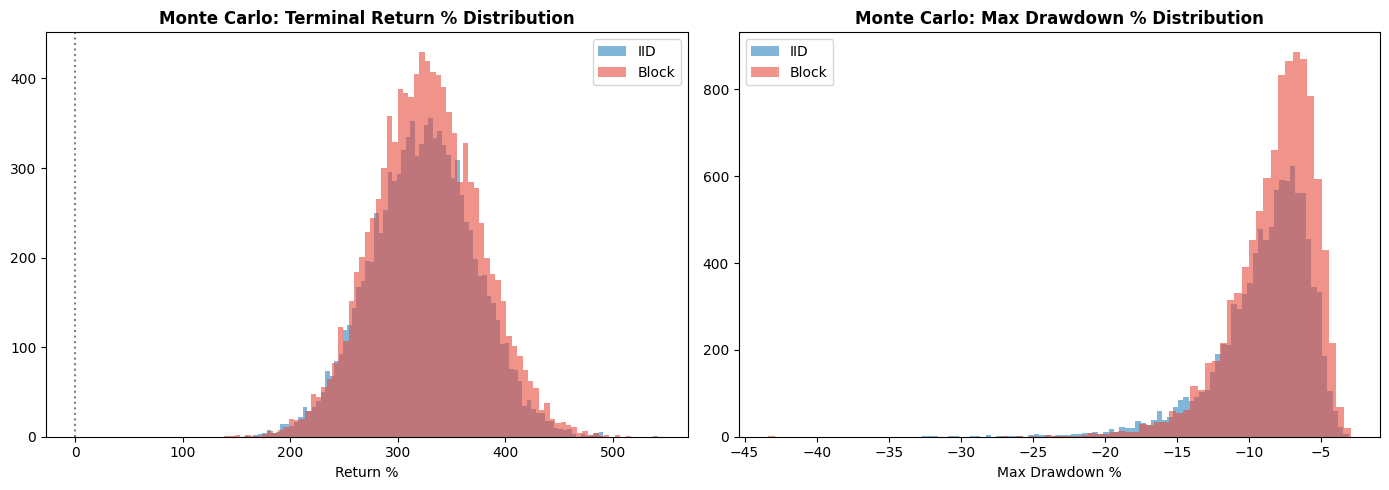

In [16]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist((mc_iid_final - 100_000) / 100_000 * 100, bins=80, alpha=0.6, label='IID', color='#2E86C1')
axes[0].hist((mc_block_final - 100_000) / 100_000 * 100, bins=80, alpha=0.6, label='Block', color='#E74C3C')
axes[0].axvline(0, color='gray', linestyle=':')
axes[0].set_title('Monte Carlo: Terminal Return % Distribution', fontweight='bold')
axes[0].set_xlabel('Return %')
axes[0].legend()

axes[1].hist(mc_iid_dd, bins=80, alpha=0.6, label='IID', color='#2E86C1')
axes[1].hist(mc_block_dd, bins=80, alpha=0.6, label='Block', color='#E74C3C')
axes[1].set_title('Monte Carlo: Max Drawdown % Distribution', fontweight='bold')
axes[1].set_xlabel('Max Drawdown %')
axes[1].legend()

plt.tight_layout()
plt.show()


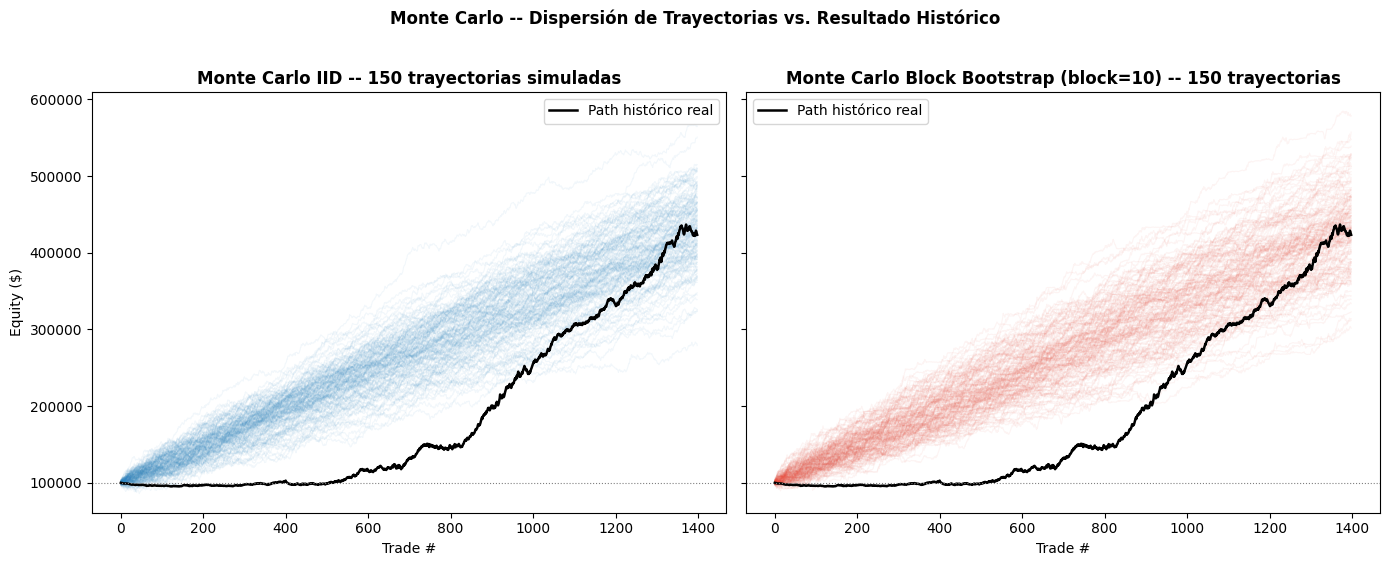

In [17]:
def simulate_paths_for_plot(pnl, n_paths=150, starting_equity=100_000.0, seed=7, block_size=None):
    rng = np.random.default_rng(seed)
    n = len(pnl)
    paths = np.empty((n_paths, n))
    for i in range(n_paths):
        if block_size is None:
            sample = rng.choice(pnl, size=n, replace=True)
        else:
            n_blocks_needed = int(np.ceil(n / block_size))
            starts = rng.integers(0, n - block_size + 1, size=n_blocks_needed)
            sample = np.concatenate([pnl[s:s + block_size] for s in starts])[:n]
        paths[i] = starting_equity + np.cumsum(sample)
    return paths

paths_iid = simulate_paths_for_plot(pnl_series, n_paths=150, block_size=None)
paths_block = simulate_paths_for_plot(pnl_series, n_paths=150, block_size=10)

# Path histórico real (el único que de verdad ocurrió)
real_equity = 100_000.0 + np.cumsum(pnl_series)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

for i in range(paths_iid.shape[0]):
    axes[0].plot(paths_iid[i], color='#2E86C1', alpha=0.06, linewidth=0.8)
axes[0].plot(real_equity, color='black', linewidth=1.8, label='Path histórico real')
axes[0].axhline(100_000, color='gray', linestyle=':', linewidth=0.8)
axes[0].set_title('Monte Carlo IID -- 150 trayectorias simuladas', fontweight='bold')
axes[0].set_xlabel('Trade #')
axes[0].set_ylabel('Equity ($)')
axes[0].legend()

for i in range(paths_block.shape[0]):
    axes[1].plot(paths_block[i], color='#E74C3C', alpha=0.06, linewidth=0.8)
axes[1].plot(real_equity, color='black', linewidth=1.8, label='Path histórico real')
axes[1].axhline(100_000, color='gray', linestyle=':', linewidth=0.8)
axes[1].set_title('Monte Carlo Block Bootstrap (block=10) -- 150 trayectorias', fontweight='bold')
axes[1].set_xlabel('Trade #')
axes[1].legend()

plt.suptitle('Monte Carlo -- Dispersión de Trayectorias vs. Resultado Histórico', fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [18]:
# --- Tradeify-style EOD trailing drawdown simulator (mirrors Development cell [10]) ---
def simulate_eod_trailing_breach(daily_pnl, starting_balance, max_dd, lock_buffer=100.0):
    """Replays Tradeify's EOD trailing drawdown mechanic on a sequence of daily P&L.
    Floor recalculates only at end-of-day, locks permanently once EOD balance
    reaches starting_balance + max_dd + lock_buffer.
    Returns: dict with breach info and the full floor/balance/buffer series.
    """
    balance = starting_balance
    floor = starting_balance - max_dd
    lock_trigger = starting_balance + max_dd + lock_buffer
    locked = False
    locked_floor = starting_balance + lock_buffer
    balances, floors, buffers = [balance], [floor], [balance - floor]
    breach_day = None
    for i, pnl in enumerate(daily_pnl):
        balance += pnl
        if balance <= floor and breach_day is None:
            breach_day = i
        if not locked:
            if balance >= lock_trigger:
                locked = True
                floor = locked_floor
        else:
            floor = max(floor, balance - max_dd)
        balances.append(balance)
        floors.append(floor)
        buffers.append(balance - floor)
        if breach_day is not None:
            break
    return {
        "breached": breach_day is not None,
        "breach_day_index": breach_day,
        "min_buffer_usd": min(buffers),
        "final_balance": balances[-1],
        "balances": balances,
        "floors": floors,
        "buffers": buffers,
    }

tradeify_tiers = {
    "50K":  {"starting_balance": 50_000,  "max_dd": 2_000},
    "100K": {"starting_balance": 100_000, "max_dd": 3_500},
    "150K": {"starting_balance": 150_000, "max_dd": 5_000},
}

In [19]:
# --- breach probability via Monte Carlo (place right after the MC histograms, cell [16]) ---
def mc_breach_probability(pnl, starting_balance, max_dd, n_sims=10_000, block_size=10, seed=99):
    rng = np.random.default_rng(seed)
    n = len(pnl)
    breaches = 0
    for _ in range(n_sims):
        n_blocks_needed = int(np.ceil(n / block_size))
        starts = rng.integers(0, n - block_size + 1, size=n_blocks_needed)
        sample = np.concatenate([pnl[s:s + block_size] for s in starts])[:n]
        result = simulate_eod_trailing_breach(sample, starting_balance, max_dd)
        if result["breached"]:
            breaches += 1
    return breaches / n_sims

print("=== Tradeify EOD Trailing Drawdown -- Breach Probability (Block Bootstrap, 10,000 sims) ===")
for tier, params in tradeify_tiers.items():
    p_breach = mc_breach_probability(pnl_series, **params)  # pnl_series already defined in cell [13]
    print(f"{tier}: P(breach over {len(pnl_series)} trades) = {p_breach*100:.2f}%")

=== Tradeify EOD Trailing Drawdown -- Breach Probability (Block Bootstrap, 10,000 sims) ===
50K: P(breach over 1399 trades) = 100.00%
100K: P(breach over 1399 trades) = 100.00%
150K: P(breach over 1399 trades) = 100.00%



## 5. Parameter Sensitivity Analysis

Grid over `ib_pct_min` x (`tp_mult`, `sl_mult`) around the blueprint
defaults (0.55%, 0.60, 0.40). A robust edge should show a broad plateau of
acceptable profit factor/return around the chosen point, not an isolated
spike -- an isolated spike surrounded by poor results at nearby parameters is
the textbook signature of curve-fitting to the in-sample noise.


In [20]:

ib_pct_grid = [0.35, 0.45, 0.55, 0.65, 0.75, 0.85, 1.00]
tp_sl_grid = [(0.50, 0.35), (0.60, 0.40), (0.70, 0.45), (0.80, 0.50)]

sensitivity_rows = []
for ib_pct in ib_pct_grid:
    for tp_m, sl_m in tp_sl_grid:
        cfg_try = IBBConfig(**{**base_cfg.__dict__, "ib_pct_min": ib_pct,
                                 "tp_mult": tp_m, "sl_mult": sl_m})
        t = run_backtest(df_raw, cfg_try)
        m = compute_metrics(t)
        sensitivity_rows.append({
            "ib_pct_min": ib_pct, "tp_mult": tp_m, "sl_mult": sl_m,
            "trades": m.get('total_trades', 0),
            "win_rate_pct": m.get('win_rate_pct', np.nan),
            "profit_factor": m.get('profit_factor', np.nan),
            "total_return_pct": m.get('total_return_pct', np.nan),
            "max_dd_pct": m.get('max_drawdown_pct', np.nan),
        })

sensitivity_df = pd.DataFrame(sensitivity_rows)
sensitivity_df


,ib_pct_min,tp_mult,sl_mult,trades,win_rate_pct,profit_factor,total_return_pct,max_dd_pct
0,0.35,0.5,0.35,3015,47.131012,1.325281,260.59675,-21.899321
1,0.35,0.6,0.40,3015,48.723051,1.438217,372.61600,-17.072220
2,0.35,0.7,0.45,3015,49.917081,1.464948,421.68850,-9.360426
3,0.35,0.8,0.50,3015,50.514096,1.461960,446.89050,-10.889476
4,0.45,0.5,0.35,2587,48.743719,1.368988,271.40125,-11.925197
5,0.45,0.6,0.40,2587,50.173947,1.480110,374.80400,-9.014051
6,0.45,0.7,0.45,2587,51.256281,1.501179,416.98300,-8.834466
7,0.45,0.8,0.50,2587,51.488210,1.488155,434.46150,-9.071918
8,0.55,0.5,0.35,2170,50.138249,1.407183,270.63500,-7.005147
9,0.55,0.6,0.40,2170,51.059908,1.502716,356.21400,-7.281756


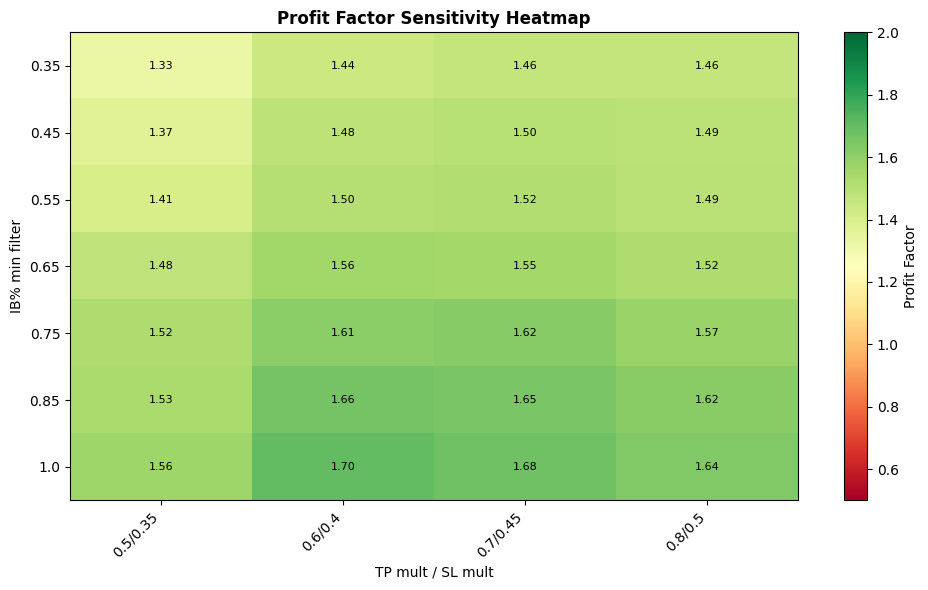

In [21]:

pivot_pf = sensitivity_df.pivot_table(
    index='ib_pct_min', columns=['tp_mult', 'sl_mult'], values='profit_factor'
)

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(pivot_pf.values, cmap='RdYlGn', aspect='auto', vmin=0.5, vmax=2.0)
ax.set_xticks(range(len(pivot_pf.columns)))
ax.set_xticklabels([f"{tp}/{sl}" for tp, sl in pivot_pf.columns], rotation=45, ha='right')
ax.set_yticks(range(len(pivot_pf.index)))
ax.set_yticklabels(pivot_pf.index)
ax.set_xlabel('TP mult / SL mult')
ax.set_ylabel('IB% min filter')
ax.set_title('Profit Factor Sensitivity Heatmap', fontweight='bold')
for i in range(len(pivot_pf.index)):
    for j in range(len(pivot_pf.columns)):
        val = pivot_pf.values[i, j]
        if np.isfinite(val):
            ax.text(j, i, f"{val:.2f}", ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=ax, label='Profit Factor')
plt.tight_layout()
plt.show()



## 6. Sub-Period (Yearly) Stability

Checks whether the edge is consistent across years, or concentrated in one
regime (e.g. 2020 COVID volatility spike, 2022 bear market). A strategy that
only works in one calendar year is a regime-fit, not a structural edge.


In [22]:

traded_full = traded_full.copy()
traded_full['year'] = pd.to_datetime(traded_full['entry_time']).dt.year

yearly_rows = []
for year, grp in traded_full.groupby('year'):
    wins = grp[grp['pnl_usd'] > 0]
    losses = grp[grp['pnl_usd'] <= 0]
    gross_profit = wins['pnl_usd'].sum()
    gross_loss = -losses['pnl_usd'].sum()
    pf = gross_profit / gross_loss if gross_loss > 0 else np.inf
    yearly_rows.append({
        "year": year,
        "trades": len(grp),
        "win_rate_pct": len(wins) / len(grp) * 100.0 if len(grp) else np.nan,
        "profit_factor": pf,
        "total_pnl_usd": grp['pnl_usd'].sum(),
    })

yearly_df = pd.DataFrame(yearly_rows)
yearly_df


,year,trades,win_rate_pct,profit_factor,total_pnl_usd
0,2009,28,21.428571,0.237332,-2378.0
1,2010,96,46.875000,0.758340,-2079.0
2,2011,105,48.571429,1.093113,1041.0
3,2012,64,48.437500,1.042779,282.0
4,2013,24,54.166667,1.703297,1344.0
5,2014,48,50.000000,1.106806,703.0
6,2015,67,44.776119,0.969320,-402.0
7,2016,62,50.000000,1.047800,578.0
8,2017,19,47.368421,1.273547,1092.0
9,2018,91,51.648352,1.512032,13958.0


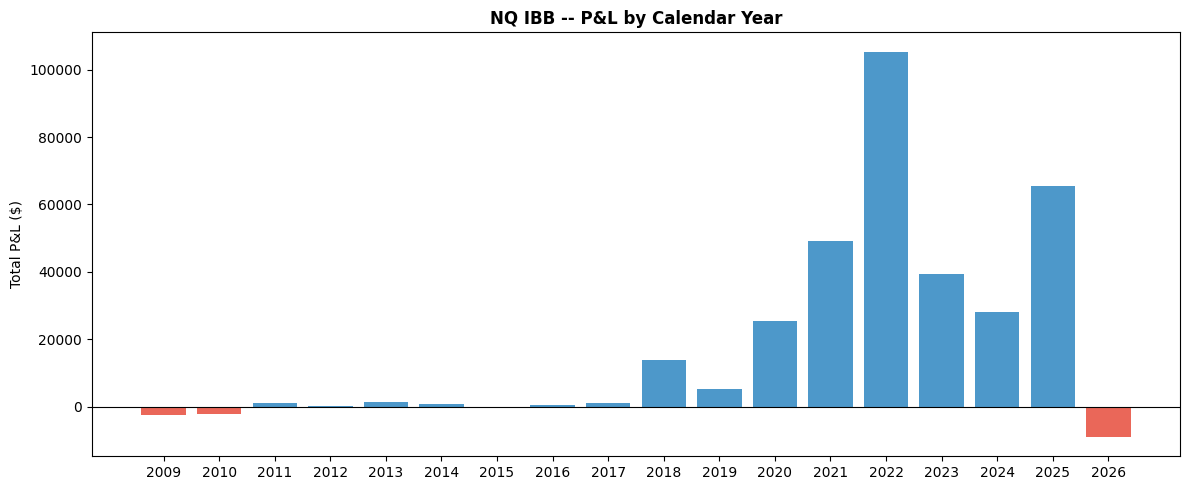

Profitable years: 14 / 18


In [23]:

fig, ax = plt.subplots(figsize=(12, 5))
colors = ['#2E86C1' if x >= 0 else '#E74C3C' for x in yearly_df['total_pnl_usd']]
ax.bar(yearly_df['year'].astype(str), yearly_df['total_pnl_usd'], color=colors, alpha=0.85)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('NQ IBB -- P&L by Calendar Year', fontweight='bold')
ax.set_ylabel('Total P&L ($)')
plt.tight_layout()
plt.show()

n_profitable_years = (yearly_df['total_pnl_usd'] > 0).sum()
print(f"Profitable years: {n_profitable_years} / {len(yearly_df)}")


# 7. CONTRACT RESIZING: NQ (1x, $20/pt) -> MNQ (Nx, $2/pt) para encajar en DD del prop firm

In [24]:

mnq_contract_range = list(range(1, 11))  # 1..10 MNQ = 0.1x .. 1.0x de un contrato NQ

resize_rows = []
for n in mnq_contract_range:
    cfg_mnq = IBBConfig(**{**base_cfg.__dict__, "point_value": 2.0, "contracts": n})
    t_mnq = run_backtest(df_raw, cfg_mnq)
    m_mnq = compute_metrics(t_mnq)

    traded_mnq = t_mnq[t_mnq['traded']].sort_values('entry_time').reset_index(drop=True)
    pnl_mnq = traded_mnq['pnl_usd'].values

    row = {
        "mnq_contracts": n,
        "nq_equivalent": n / 10.0,
        "total_trades": m_mnq.get('total_trades', 0),
        "total_return_pct": m_mnq.get('total_return_pct', np.nan),
        "max_drawdown_pct": m_mnq.get('max_drawdown_pct', np.nan),
        "expectancy_usd": m_mnq.get('expectancy_usd', np.nan),
    }
    for tier, params in tradeify_tiers.items():
        p_breach = mc_breach_probability(pnl_mnq, **params, n_sims=10_000,
                                          block_size=10, seed=99)
        row[f"breach_prob_{tier}_pct"] = p_breach * 100
    resize_rows.append(row)

resize_df = pd.DataFrame(resize_rows)
resize_df

,mnq_contracts,nq_equivalent,total_trades,total_return_pct,max_drawdown_pct,expectancy_usd,breach_prob_50K_pct,breach_prob_100K_pct,breach_prob_150K_pct
0,1,0.1,1399,32.3457,-1.104683,23.120586,7.63,0.05,0.00
1,2,0.2,1399,64.6914,-1.764704,46.241172,94.88,17.28,1.09
2,3,0.3,1399,97.0371,-2.203563,69.361758,100.00,83.92,22.39
3,4,0.4,1399,129.3828,-2.683607,92.482345,100.00,98.71,69.39
4,5,0.5,1399,161.7285,-3.218084,115.602931,100.00,100.00,94.88
5,6,0.6,1399,194.0742,-3.710786,138.723517,100.00,100.00,99.32
6,7,0.7,1399,226.4199,-4.166427,161.844103,100.00,100.00,100.00
7,8,0.8,1399,258.7656,-4.589037,184.964689,100.00,100.00,100.00
8,9,0.9,1399,291.1113,-5.058879,208.085275,100.00,100.00,100.00
9,10,1.0,1399,323.4570,-5.604998,231.205861,100.00,100.00,100.00


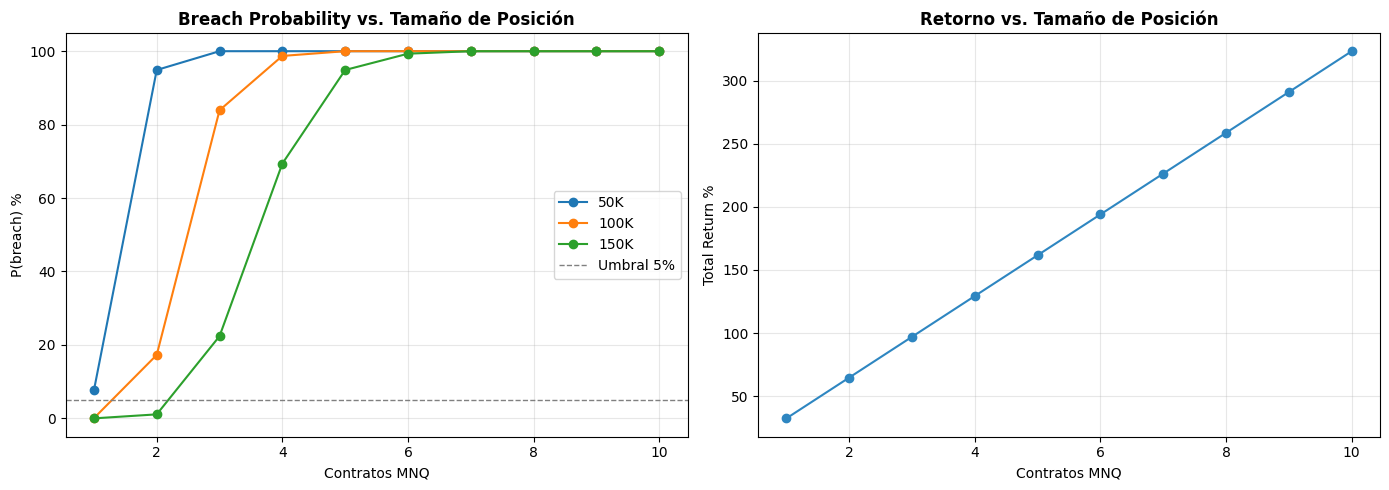

50K: máximo de contratos MNQ con P(breach) <= 5%: None
100K: máximo de contratos MNQ con P(breach) <= 5%: 1
150K: máximo de contratos MNQ con P(breach) <= 5%: 2


In [25]:
# --- Gráfico: trade-off breach probability vs. contratos MNQ, por tier ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for tier in tradeify_tiers:
    axes[0].plot(resize_df['mnq_contracts'], resize_df[f'breach_prob_{tier}_pct'],
                 marker='o', label=tier)
axes[0].axhline(5.0, color='gray', linestyle='--', linewidth=1, label='Umbral 5%')
axes[0].set_xlabel('Contratos MNQ')
axes[0].set_ylabel('P(breach) %')
axes[0].set_title('Breach Probability vs. Tamaño de Posición', fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(resize_df['mnq_contracts'], resize_df['total_return_pct'],
             marker='o', color='#2E86C1')
axes[1].set_xlabel('Contratos MNQ')
axes[1].set_ylabel('Total Return %')
axes[1].set_title('Retorno vs. Tamaño de Posición', fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# --- Recomendación automática: mayor N con breach_prob <= 5% por tier ---
for tier in tradeify_tiers:
    ok = resize_df[resize_df[f'breach_prob_{tier}_pct'] <= 5.0]
    best_n = ok['mnq_contracts'].max() if len(ok) else None
    print(f"{tier}: máximo de contratos MNQ con P(breach) <= 5%: {best_n}")